<a href="https://colab.research.google.com/github/njalagam23/neural-networks-from-scratch/blob/main/day05_model_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

rng = np.random.default_rng(42)

# Generate 400 synthetic customers
n = 400

usage = rng.uniform(0, 40, n)
tenure = rng.integers(1, 61, n)
tickets = rng.poisson(1.5, n)

X = np.column_stack([usage, tenure, tickets])

# Simulated churn outcomes
logits = 0.9 - 0.14 * usage - 0.035 * tenure + 0.9 * tickets
true_probs = 1 / (1 + np.exp(-logits))

y = (rng.random(n) < true_probs).astype(float).reshape(-1, 1)

# Train/test split
idx = rng.permutation(n)
train_idx, test_idx = idx[:320], idx[320:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Standardize using training statistics only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (320, 3)
Testing: (80, 3)


In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

torch.manual_seed(42)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print(X_train_t.shape)
print(y_train_t.shape)

torch.Size([320, 3])
torch.Size([320, 1])


In [ ]:
class ChurnModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden = nn.Linear(3, 8)
        self.output = nn.Linear(8, 1)

    def forward(self, x):

        x = self.hidden(x)
        x = torch.relu(x)

        x = self.output(x)

        return x


model = ChurnModel()

print(model)

ChurnModel(
  (hidden): Linear(in_features=3, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
)


In [ ]:
def train_model(model, X, y, epochs=600, lr=0.2):

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr
    )

    history = []

    model.train()

    for epoch in range(epochs):

        logits = model(X)

        loss = criterion(logits, y)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        history.append(loss.item())

        if (epoch + 1) % 100 == 0:
            print(
                f"Epoch {epoch+1}: "
                f"Loss = {loss.item():.4f}"
            )

    return history

In [ ]:
loss_history = train_model(
    model,
    X_train_t,
    y_train_t
)

Epoch 100: Loss = 0.3695
Epoch 200: Loss = 0.3398
Epoch 300: Loss = 0.3336
Epoch 400: Loss = 0.3298
Epoch 500: Loss = 0.3269
Epoch 600: Loss = 0.3251


In [ ]:
model.eval()

with torch.no_grad():

    test_logits = model(X_test_t)

    probabilities = torch.sigmoid(test_logits)

    predictions = (
        probabilities >= 0.5
    ).int().numpy().flatten()

actual = y_test_t.int().numpy().flatten()

accuracy = accuracy_score(actual, predictions)
precision = precision_score(actual, predictions, zero_division=0)
recall = recall_score(actual, predictions, zero_division=0)
f1 = f1_score(actual, predictions, zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(actual, predictions))

print("\nClassification Report:")
print(classification_report(actual, predictions, zero_division=0))

Accuracy: 0.8375
Precision: 0.9412
Recall: 0.5714
F1 Score: 0.7111

Confusion Matrix:
[[51  1]
 [12 16]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.98      0.89        52
           1       0.94      0.57      0.71        28

    accuracy                           0.84        80
   macro avg       0.88      0.78      0.80        80
weighted avg       0.86      0.84      0.83        80



In [ ]:
new_customer = np.array([[8, 5, 4]])

# Use mean and std from Day 3 preprocessing
new_customer_scaled = (new_customer - mean) / std

new_customer_t = torch.tensor(
    new_customer_scaled,
    dtype=torch.float32
)

model.eval()

with torch.no_grad():

    logit = model(new_customer_t)

    churn_probability = torch.sigmoid(logit).item()

print(
    f"Churn probability: "
    f"{churn_probability:.2%}"
)

Churn probability: 88.57%


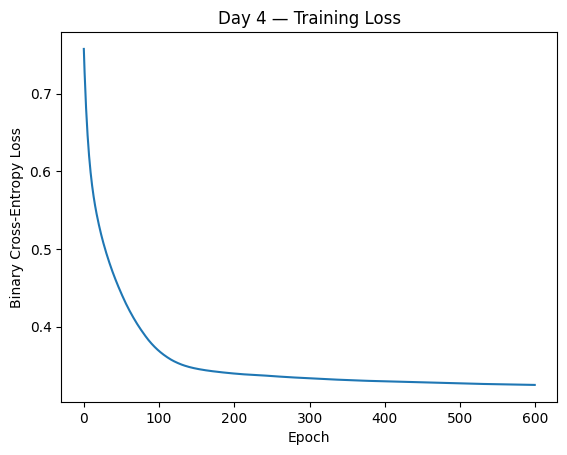

In [ ]:
plt.plot(loss_history)

plt.title("Day 4 — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

plt.show()

In [ ]:
assert X_train_t.shape == (320, 3)
assert y_train_t.shape == (320, 1)

assert len(loss_history) == 600
assert np.isfinite(loss_history).all()

assert loss_history[-1] < loss_history[0]

assert 0 <= accuracy <= 1
assert 0 <= precision <= 1
assert 0 <= recall <= 1
assert 0 <= f1 <= 1

print("All basic checks passed!")

All basic checks passed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model.eval()

with torch.no_grad():
    logits = model(X_test_t)
    probabilities = torch.sigmoid(logits).numpy().flatten()

actual = y_test_t.numpy().flatten()

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

    predictions = (probabilities >= threshold).astype(int)

    accuracy = accuracy_score(actual, predictions)
    precision = precision_score(actual, predictions, zero_division=0)
    recall = recall_score(actual, predictions, zero_division=0)
    f1 = f1_score(actual, predictions, zero_division=0)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Accuracy: {accuracy:.3f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.3 | Accuracy: 0.825 | Precision: 0.792 | Recall: 0.679 | F1: 0.731
Threshold: 0.4 | Accuracy: 0.825 | Precision: 0.818 | Recall: 0.643 | F1: 0.720
Threshold: 0.5 | Accuracy: 0.838 | Precision: 0.941 | Recall: 0.571 | F1: 0.711
Threshold: 0.6 | Accuracy: 0.762 | Precision: 0.909 | Recall: 0.357 | F1: 0.513
Threshold: 0.7 | Accuracy: 0.750 | Precision: 0.900 | Recall: 0.321 | F1: 0.474


In [ ]:
from sklearn.metrics import accuracy_score

model.eval()

with torch.no_grad():
    train_probs = torch.sigmoid(model(X_train_t))
    test_probs = torch.sigmoid(model(X_test_t))

train_preds = (train_probs >= 0.5).int().numpy().flatten()
test_preds = (test_probs >= 0.5).int().numpy().flatten()

train_actual = y_train_t.int().numpy().flatten()
test_actual = y_test_t.int().numpy().flatten()

train_accuracy = accuracy_score(train_actual, train_preds)
test_accuracy = accuracy_score(test_actual, test_preds)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Difference: {train_accuracy - test_accuracy:.4f}")

Training Accuracy: 0.8719
Test Accuracy: 0.8375
Difference: 0.0344


In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# Recreate the original synthetic dataset
rng = np.random.default_rng(42)
n = 400

usage = rng.uniform(0, 40, n)
tenure = rng.integers(1, 61, n)
tickets = rng.poisson(1.5, n)

X = np.column_stack([usage, tenure, tickets])

logits = (
    0.9
    - 0.14 * usage
    - 0.035 * tenure
    + 0.9 * tickets
)

true_probs = 1 / (1 + np.exp(-logits))
y = (rng.random(n) < true_probs).astype(int)

# First: reserve 20% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second: take 25% of the remaining 80%
# That gives 60% train, 20% validation, 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

# Fit scaling ONLY on training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (240, 3)
Validation: (80, 3)
Testing: (80, 3)


In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

print(X_train_t.shape)
print(y_train_t.shape)

torch.Size([240, 3])
torch.Size([240, 1])


In [3]:
class ChurnModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden = nn.Linear(3, 8)
        self.output = nn.Linear(8, 1)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        x = self.output(x)
        return x

model = ChurnModel()

In [4]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.2)

train_losses = []
val_losses = []

for epoch in range(600):

    # Training
    model.train()

    train_logits = model(X_train_t)
    train_loss = criterion(train_logits, y_train_t)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch+1} | "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Validation Loss: {val_loss.item():.4f}"
        )

Epoch 100 | Train Loss: 0.3843 | Validation Loss: 0.3606
Epoch 200 | Train Loss: 0.3564 | Validation Loss: 0.3383
Epoch 300 | Train Loss: 0.3526 | Validation Loss: 0.3418
Epoch 400 | Train Loss: 0.3512 | Validation Loss: 0.3411
Epoch 500 | Train Loss: 0.3501 | Validation Loss: 0.3409
Epoch 600 | Train Loss: 0.3477 | Validation Loss: 0.3413


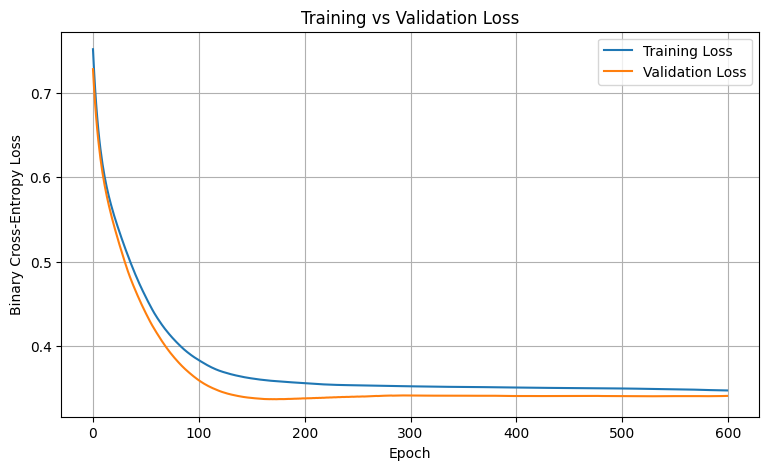

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [6]:
best_epoch = val_losses.index(min(val_losses)) + 1

print("Final Training Loss:", round(train_losses[-1], 4))
print("Final Validation Loss:", round(val_losses[-1], 4))
print("Lowest Validation Loss:", round(min(val_losses), 4))
print("Best Epoch:", best_epoch)

Final Training Loss: 0.3477
Final Validation Loss: 0.3413
Lowest Validation Loss: 0.3373
Best Epoch: 174


In [7]:
import copy
import torch

torch.manual_seed(42)
model = ChurnModel()

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.2)

best_val_loss = float("inf")
best_weights = None
best_epoch = 0

patience = 30
epochs_without_improvement = 0

train_losses_es = []
val_losses_es = []

for epoch in range(600):

    # Training
    model.train()

    train_logits = model(X_train_t)
    train_loss = criterion(train_logits, y_train_t)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t)

    train_losses_es.append(train_loss.item())
    val_losses_es.append(val_loss.item())

    # Check improvement
    if val_loss.item() < best_val_loss:

        best_val_loss = val_loss.item()
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    # Stop if validation hasn't improved
    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# Restore the best model
model.load_state_dict(best_weights)

print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Total Epochs Trained: {len(train_losses_es)}")

Early stopping at epoch 204
Best Epoch: 174
Best Validation Loss: 0.3373
Total Epochs Trained: 204


In [8]:
import copy
import torch
import torch.nn as nn

learning_rates = [0.01, 0.1, 0.2]

results = []

for lr in learning_rates:

    # Same initialization for fair comparison
    torch.manual_seed(42)

    experiment_model = ChurnModel()

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.SGD(
        experiment_model.parameters(),
        lr=lr
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    patience = 30
    wait = 0

    for epoch in range(600):

        experiment_model.train()

        logits = experiment_model(X_train_t)
        train_loss = criterion(logits, y_train_t)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        experiment_model.eval()

        with torch.no_grad():
            val_logits = experiment_model(X_val_t)
            val_loss = criterion(val_logits, y_val_t)

        if val_loss.item() < best_val_loss:

            best_val_loss = val_loss.item()
            best_epoch = epoch + 1

            best_weights = copy.deepcopy(
                experiment_model.state_dict()
            )

            wait = 0

        else:
            wait += 1

        if wait >= patience:
            break

    experiment_model.load_state_dict(best_weights)

    results.append({
        "learning_rate": lr,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "epochs_trained": epoch + 1
    })

for result in results:
    print(result)

{'learning_rate': 0.01, 'best_epoch': 600, 'best_val_loss': 0.5026050806045532, 'epochs_trained': 600}
{'learning_rate': 0.1, 'best_epoch': 346, 'best_val_loss': 0.3373776972293854, 'epochs_trained': 376}
{'learning_rate': 0.2, 'best_epoch': 174, 'best_val_loss': 0.3373425602912903, 'epochs_trained': 204}


In [9]:
class ChurnModel(nn.Module):

    def __init__(self, hidden_size=8):
        super().__init__()

        self.hidden = nn.Linear(3, hidden_size)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        x = self.output(x)
        return x

In [10]:
import copy

hidden_sizes = [4, 8, 16]

hidden_results = []
best_models = {}

for size in hidden_sizes:

    torch.manual_seed(42)

    experiment_model = ChurnModel(hidden_size=size)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(
        experiment_model.parameters(),
        lr=0.2
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    patience = 30
    wait = 0

    for epoch in range(600):

        experiment_model.train()

        logits = experiment_model(X_train_t)
        train_loss = criterion(logits, y_train_t)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        experiment_model.eval()

        with torch.no_grad():
            val_logits = experiment_model(X_val_t)
            val_loss = criterion(val_logits, y_val_t)

        if val_loss.item() < best_val_loss:

            best_val_loss = val_loss.item()
            best_epoch = epoch + 1

            best_weights = copy.deepcopy(
                experiment_model.state_dict()
            )

            wait = 0

        else:
            wait += 1

        if wait >= patience:
            break

    experiment_model.load_state_dict(best_weights)

    best_models[size] = experiment_model

    hidden_results.append({
        "hidden_neurons": size,
        "best_epoch": best_epoch,
        "best_val_loss": round(best_val_loss, 4),
        "epochs_trained": epoch + 1
    })

for result in hidden_results:
    print(result)

{'hidden_neurons': 4, 'best_epoch': 215, 'best_val_loss': 0.3447, 'epochs_trained': 245}
{'hidden_neurons': 8, 'best_epoch': 174, 'best_val_loss': 0.3373, 'epochs_trained': 204}
{'hidden_neurons': 16, 'best_epoch': 105, 'best_val_loss': 0.351, 'epochs_trained': 135}


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

X_test_t = torch.tensor(
    X_test, dtype=torch.float32
)

y_test_t = torch.tensor(
    y_test, dtype=torch.float32
).reshape(-1, 1)

In [12]:
best_model = best_models[8]

best_model.eval()

with torch.no_grad():
    logits = best_model(X_test_t)
    probabilities = torch.sigmoid(logits)

predictions = (
    probabilities >= 0.5
).int().numpy().flatten()

actual = y_test_t.int().numpy().flatten()

print("Accuracy:", round(accuracy_score(actual, predictions), 4))
print("Precision:", round(precision_score(actual, predictions, zero_division=0), 4))
print("Recall:", round(recall_score(actual, predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(actual, predictions, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(actual, predictions))

print("\nClassification Report:")
print(classification_report(actual, predictions, zero_division=0))

Accuracy: 0.85
Precision: 0.75
Recall: 0.6
F1 Score: 0.6667

Confusion Matrix:
[[56  4]
 [ 8 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90        60
           1       0.75      0.60      0.67        20

    accuracy                           0.85        80
   macro avg       0.81      0.77      0.78        80
weighted avg       0.84      0.85      0.84        80

